# RUKOPYS — Exploratory Data Analysis

**Purpose:** explore the annotated **training metadata** for the [RUKOPYS dataset](https://huggingface.co/datasets/UkrainianCatholicUniversity/rukopys), identify data challenges, and export figures for our midterm presentation.

This notebook:
- reads `train/metadata.jsonl` without downloading all document images;
- counts pages and regions, analyzes sources and region types;
- examines transcription lengths, language, legibility and bounding boxes;
- checks the page-level train/validation split;
- saves figures and summary tables.

**Scope:** the statistics here describe the labeled training metadata, **not** Kaggle's hidden test set or necessarily the complete Hugging Face `full` configuration. Charts are computed when you run the cells; there are no fabricated counts.

**Requirements:** `pandas`, `numpy`, `matplotlib`, `huggingface_hub` (already listed in the project requirements).

In [2]:
# Google Colab setup: clone the code repository only if needed.
%pip -q install huggingface_hub pandas numpy matplotlib
from pathlib import Path
import subprocess
import sys

REPO_DIR = Path("/content/mavka-rukopys")
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "https://github.com/marharytapaduchak/mavka-rukopys.git", str(REPO_DIR)], check=True)

sys.path.insert(0, str(REPO_DIR / "src"))
%cd /content/mavka-rukopys
from rukopys.utils import digest
print("Repository ready:", REPO_DIR)


/content/mavka-rukopys
Repository ready: /content/mavka-rukopys


In [3]:
from pathlib import Path
import json
import math
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download, dataset_info

DATASET_ID = "UkrainianCatholicUniversity/rukopys"
METADATA_FILE = "train/metadata.jsonl"
SEED = 42
VALIDATION_FRACTION = 0.20

# Set to a local JSONL path if metadata is already downloaded.
LOCAL_METADATA_PATH = None
OUTPUT_DIR = Path("results/rukopys_eda")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 170, "font.size": 11})

def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


## 1. Load metadata
Only annotations are downloaded; full images are not necessary for these statistics.

In [4]:
if LOCAL_METADATA_PATH:
    metadata_path = Path(LOCAL_METADATA_PATH)
    revision = "local-file"
else:
    revision = dataset_info(DATASET_ID).sha
    metadata_path = Path(hf_hub_download(
        repo_id=DATASET_ID,
        filename=METADATA_FILE,
        repo_type="dataset",
        revision=revision,
    ))

with metadata_path.open(encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

assert records, "Metadata file is empty."
print(f"Metadata: {metadata_path}")
print(f"Dataset revision: {revision}")
print(f"Number of pages: {len(records):,}")
print("Example fields:", list(records[0]))
print("Example region fields:", list((records[0].get("regions") or [{}])[0]))


metadata.jsonl:   0%|          | 0.00/4.48M [00:00<?, ?B/s]

Metadata: /root/.cache/huggingface/hub/datasets--UkrainianCatholicUniversity--rukopys/snapshots/aaebe5290a3ae7ea8a2fa77cf31bb872761c7310/train/metadata.jsonl
Dataset revision: aaebe5290a3ae7ea8a2fa77cf31bb872761c7310
Number of pages: 1,330
Example fields: ['file_name', 'image_width', 'image_height', 'source', 'source_detail', 'annotation_source', 'regions']
Example region fields: ['bbox', 'type', 'language', 'legibility', 'text']


## 2. Build page-level and region-level tables

In [5]:
page_rows, region_rows = [], []
for page in records:
    filename = page["file_name"]
    regions = page.get("regions") or []
    page_rows.append({
        "file_name": filename,
        "source": page.get("source", "unknown"),
        "source_detail": page.get("source_detail"),
        "content_type": page.get("content_type"),
        "subject": page.get("subject"),
        "n_regions": len(regions),
        "image_width": page.get("image_width"),
        "image_height": page.get("image_height"),
    })
    for idx, r in enumerate(regions):
        bbox = r.get("bbox")
        text = r.get("text") if isinstance(r.get("text"), str) else ""
        region_rows.append({
            "file_name": filename,
            "source": page.get("source", "unknown"),
            "region_index": idx,
            "type": r.get("type", "unknown"),
            "language": r.get("language", "missing"),
            "legibility": r.get("legibility", "missing"),
            "text": text,
            "n_characters": len(text),
            "n_words": len(text.split()),
            "has_text": bool(text.strip()),
            "bbox": bbox,
            "image_width": page.get("image_width"),
            "image_height": page.get("image_height"),
        })
pages = pd.DataFrame(page_rows)
regions = pd.DataFrame(region_rows)
print(f"Pages: {len(pages):,} | Regions: {len(regions):,}")
display(pages.head(3))
display(regions.drop(columns="text").head(3))


Pages: 1,330 | Regions: 25,651


,file_name,source,source_detail,content_type,subject,n_regions,image_width,image_height
0,images/09ba34df-2665-452c-9ef4-6998a5e7944c.jpg,dictation,national_dictation,None,None,23,3468,4624
1,images/3c54f7fd-3fe1-4f4b-8045-0efe0d656fbd.jpg,dictation,national_dictation,None,None,19,3000,4000
2,images/2accc0fa-0368-4a59-9b16-ae107479c630.jpg,dictation,national_dictation,None,None,24,2296,2798


,file_name,source,region_index,type,language,legibility,n_characters,n_words,has_text,bbox,image_width,image_height
0,images/09ba34df-2665-452c-9ef4-6998a5e7944c.jpg,dictation,0,handwritten,uk,legible,13,2,True,"[1213, 350, 2052, 530]",3468,4624
1,images/09ba34df-2665-452c-9ef4-6998a5e7944c.jpg,dictation,1,handwritten,uk,legible,39,6,True,"[395, 466, 2987, 866]",3468,4624
2,images/09ba34df-2665-452c-9ef4-6998a5e7944c.jpg,dictation,2,handwritten,uk,legible,39,6,True,"[151, 664, 2850, 1046]",3468,4624


## 3. Overview and source distribution

,Metric,Value
0,Pages,1330.00
1,Annotated regions,25651.00
2,Sources,4.00
3,Regions with non-empty text,25376.00
4,Mean regions per page,19.29
5,Median regions per page,20.00


,source,pages
0,school,682
1,dictation,359
2,university,162
3,archive,127


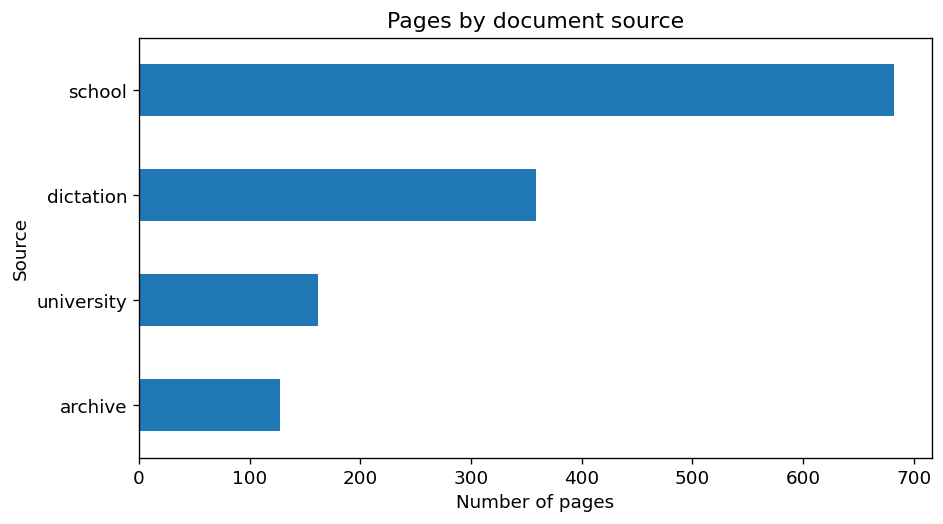

In [6]:
summary = pd.DataFrame([
    ("Pages", len(pages)),
    ("Annotated regions", len(regions)),
    ("Sources", pages["source"].nunique()),
    ("Regions with non-empty text", int(regions["has_text"].sum())),
    ("Mean regions per page", round(pages["n_regions"].mean(), 2)),
    ("Median regions per page", float(pages["n_regions"].median())),
], columns=["Metric", "Value"])
display(summary)
display(pages["source"].value_counts().rename_axis("source").reset_index(name="pages"))

fig, ax = plt.subplots(figsize=(8, 4.5))
pages["source"].value_counts().sort_values().plot.barh(ax=ax)
ax.set(title="Pages by document source", xlabel="Number of pages", ylabel="Source")
save_figure("01_sources")


## 4. Region types and class imbalance

,region_type,count,percent
0,handwritten,21577,84.12
1,formula,2892,11.27
2,annotation,554,2.16
3,printed,308,1.20
4,table,142,0.55
5,image,119,0.46
6,graph,59,0.23


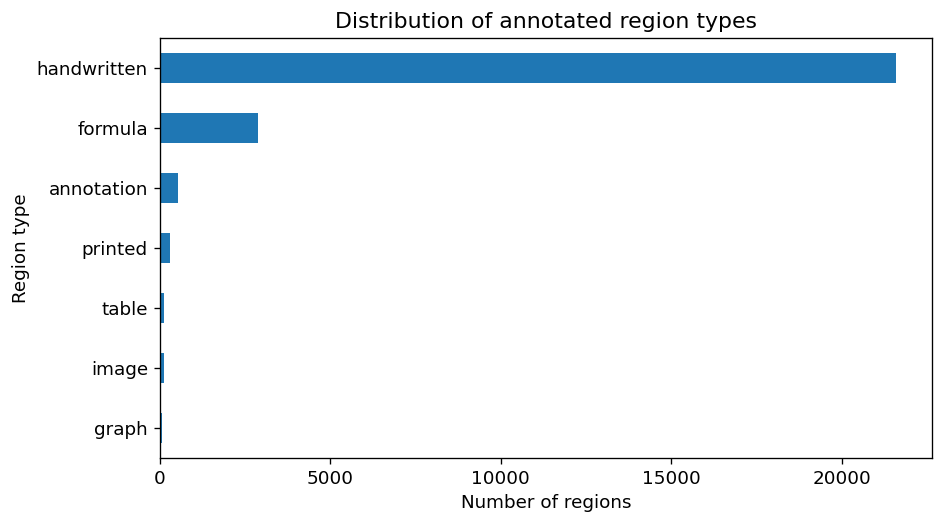

In [7]:
type_counts = regions["type"].value_counts()
type_stats = type_counts.rename_axis("region_type").reset_index(name="count")
type_stats["percent"] = (100 * type_stats["count"] / len(regions)).round(2)
display(type_stats)

fig, ax = plt.subplots(figsize=(8, 4.5))
type_counts.sort_values().plot.barh(ax=ax)
ax.set(title="Distribution of annotated region types", xlabel="Number of regions", ylabel="Region type")
save_figure("02_region_types")


## 5. Layout complexity: regions per page

,regions_per_page
count,1330.000000
mean,19.286466
std,9.525770
min,1.000000
25%,12.000000
50%,20.000000
75%,25.000000
90%,31.000000
95%,35.000000
max,81.000000


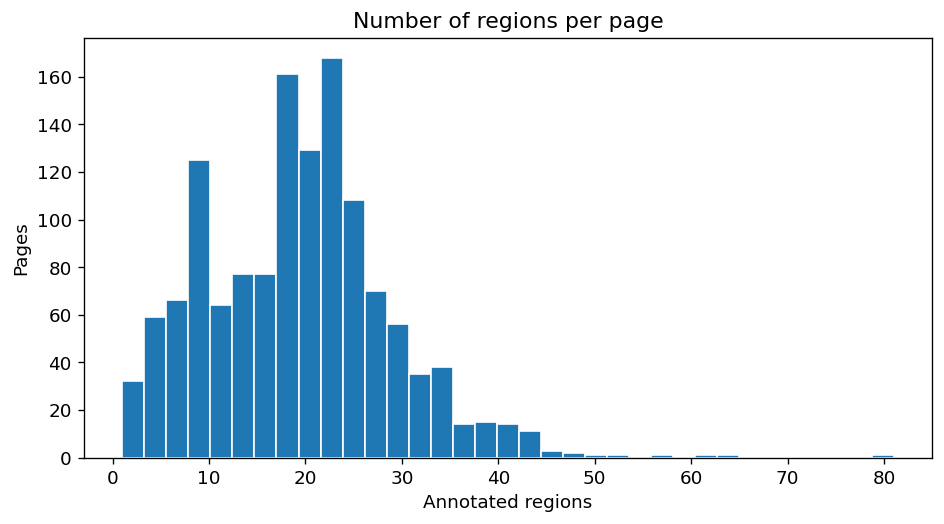

In [8]:
display(pages["n_regions"].describe(percentiles=[.25,.5,.75,.9,.95]).to_frame("regions_per_page"))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(pages["n_regions"], bins=min(35, max(5, int(np.sqrt(len(pages))))), edgecolor="white")
ax.set(title="Number of regions per page", xlabel="Annotated regions", ylabel="Pages")
save_figure("03_regions_per_page")


## 6. Transcription lengths
We analyze only **nonempty** reference transcriptions. Very long regions may require more output tokens during inference.

,characters
count,25376.000000
mean,30.181628
std,21.964110
min,1.000000
25%,15.000000
50%,30.000000
75%,40.000000
90%,50.000000
95%,59.000000
99%,89.000000


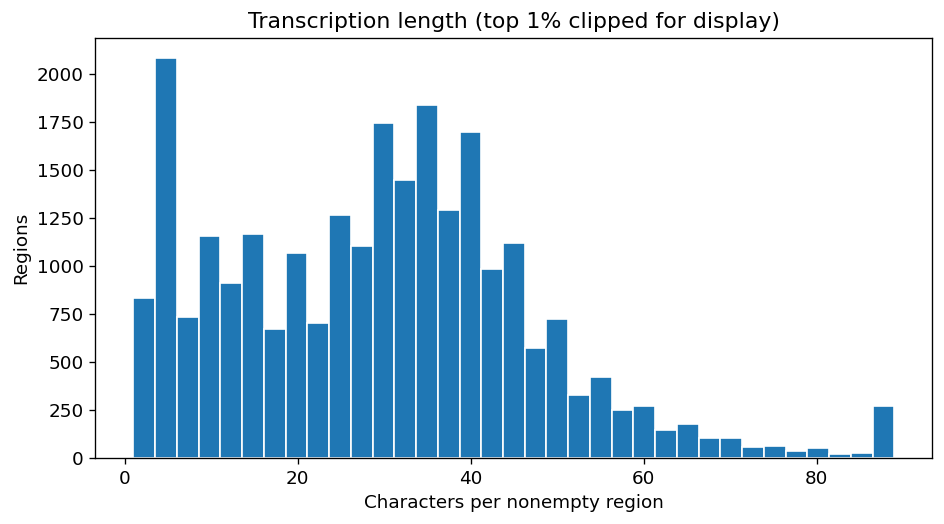

In [9]:
text_regions = regions.loc[regions["has_text"]].copy()
display(text_regions["n_characters"].describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_frame("characters"))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(text_regions["n_characters"].clip(upper=text_regions["n_characters"].quantile(.99)),
        bins=35, edgecolor="white")
ax.set(title="Transcription length (top 1% clipped for display)",
       xlabel="Characters per nonempty region", ylabel="Regions")
save_figure("04_transcription_lengths")


## 7. Language and legibility annotations
These metadata fields help identify which regions are eligible for transcription scoring in the project's data preparation code.

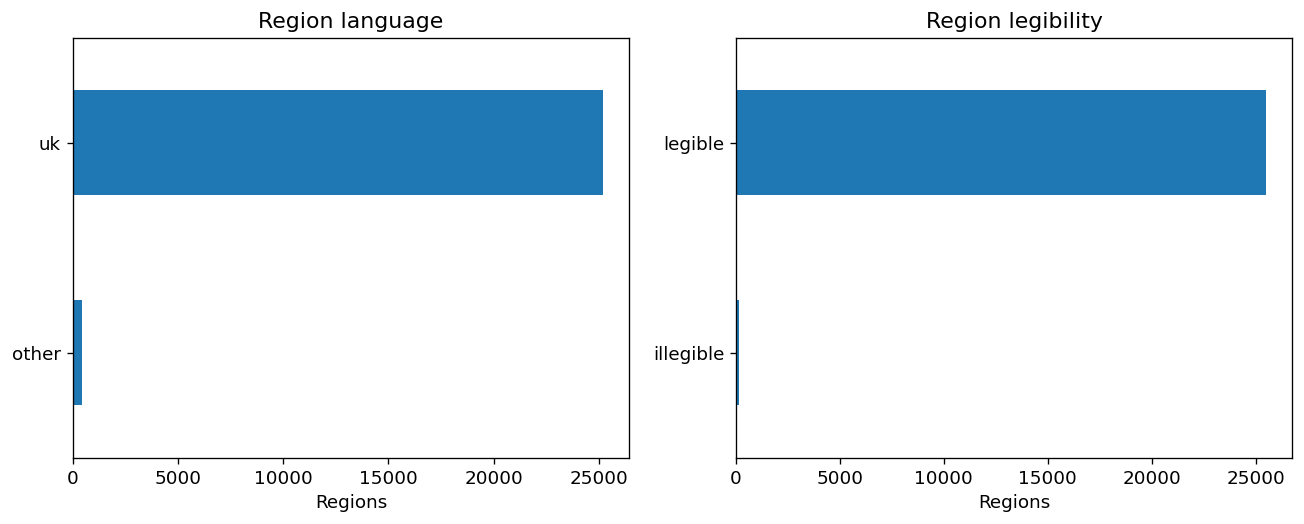

legibility,illegible,legible
type,,
annotation,29,525
formula,4,2888
graph,1,58
handwritten,95,21482
image,5,114
printed,19,289
table,0,142


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for col, ax in zip(["language", "legibility"], axes):
    regions[col].fillna("missing").value_counts().sort_values().plot.barh(ax=ax)
    ax.set(title=f"Region {col}", xlabel="Regions", ylabel="")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_language_legibility.png", bbox_inches="tight")
plt.show()
display(pd.crosstab(regions["type"], regions["legibility"].fillna("missing")))


## 8. Bounding box quality checks
Uses annotated coordinates and the page width/height from metadata; image downloads are not required.

In [11]:
def box_status(row):
    b = row["bbox"]
    if not isinstance(b, (list, tuple)) or len(b) != 4:
        return "missing_or_malformed"
    try:
        x1, y1, x2, y2 = map(float, b)
    except (TypeError, ValueError):
        return "missing_or_malformed"
    if not all(math.isfinite(v) for v in (x1, y1, x2, y2)):
        return "non_finite"
    if x2 <= x1 or y2 <= y1:
        return "non_positive_area"
    w, h = row["image_width"], row["image_height"]
    if pd.isna(w) or pd.isna(h) or float(w) <= 0 or float(h) <= 0:
        return "missing_image_dimensions"
    if x1 < 0 or y1 < 0 or x2 > w or y2 > h:
        return "out_of_image_bounds"
    return "valid"

regions["bbox_status"] = regions.apply(box_status, axis=1)
display(regions["bbox_status"].value_counts().rename_axis("status").reset_index(name="regions"))
assert pages["file_name"].is_unique, "Duplicate page identifiers detected"


,status,regions
0,valid,25651


## 9. Train/validation comparison

If a project's existing `data/split.json` is available, use it. Otherwise reproduce the **same deterministic source-stratified split logic** as `src/rukopys/data.py`. The fallback uses SHA-256 of canonical JSON, matching the helper used in the repository; we will validate that assumption below when running in the project environment.

Reconstructed split using project source-stratified logic


split,train,validation
source,,
archive,101,26
dictation,287,72
school,545,137
university,129,33


split,train,validation
type,,
annotation,2.16,2.16
formula,11.56,10.13
graph,0.25,0.14
handwritten,83.98,84.69
image,0.48,0.39
printed,1.01,1.99
table,0.57,0.49


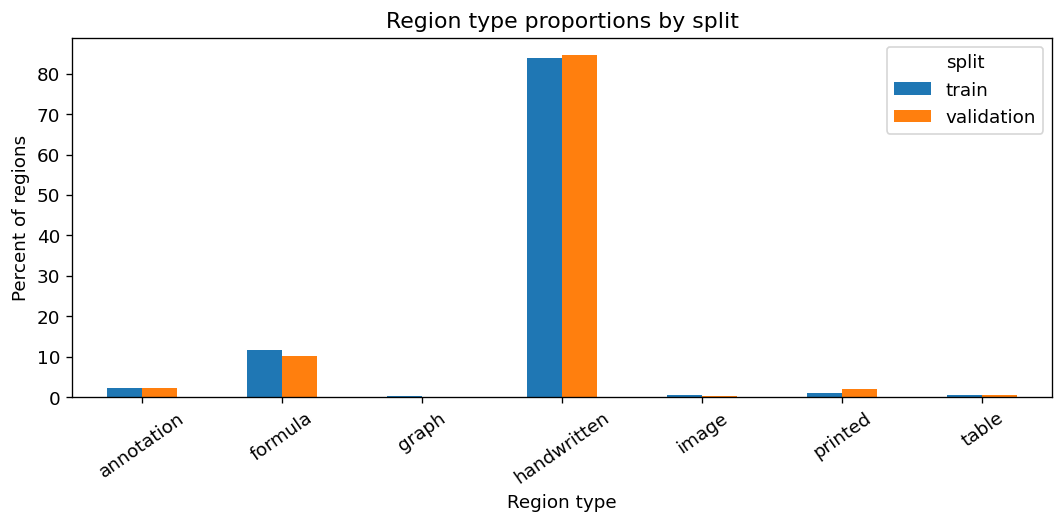

In [12]:
# Prefer existing split from the project so plots match model evaluation exactly.
split_candidates = [Path("src/work/data/split.json"), Path("data/split.json")]
split_path = next((p for p in split_candidates if p.exists()), None)

def fallback_split(pages_table):
    # Mirrors the deterministic per-source grouping implemented in src/rukopys/data.py.
    # Uses project's actual digest implementation when available.
    try:
        from rukopys.utils import digest
    except ImportError:
        try:
            from src.rukopys.utils import digest
        except ImportError as exc:
            raise RuntimeError(
                "No existing split.json found. Run from the repo root, "
                "and ensure src/rukopys is importable, or set split_path manually."
            ) from exc
    train, val = [], []
    for source, group in pages_table.groupby("source", sort=True):
        names = sorted(group["file_name"].tolist(), key=lambda name: digest([SEED, name]))
        k = min(len(names)-1, max(1, math.ceil(len(names)*VALIDATION_FRACTION))) if len(names)>1 else 0
        val.extend(names[:k])
        train.extend(names[k:])
    return {"train": train, "validation": val}

if split_path:
    split = json.loads(split_path.read_text(encoding="utf-8"))
    print("Using existing split:", split_path)
else:
    split = fallback_split(pages)
    print("Reconstructed split using project source-stratified logic")

train_ids, val_ids = set(split["train"]), set(split["validation"])
assert not (train_ids & val_ids), "Train/validation overlap"
assert train_ids | val_ids == set(pages["file_name"]), "Split does not cover all pages"

pages["split"] = pages["file_name"].map(lambda x: "train" if x in train_ids else "validation")
regions["split"] = regions["file_name"].map(lambda x: "train" if x in train_ids else "validation")
display(pd.crosstab(pages["source"], pages["split"]))
display(pd.crosstab(regions["type"], regions["split"], normalize="columns").mul(100).round(2))

distribution = pd.crosstab(regions["type"], regions["split"], normalize="columns").mul(100)
ax = distribution.plot.bar(figsize=(9,4.5), rot=35)
ax.set(title="Region type proportions by split", xlabel="Region type", ylabel="Percent of regions")
save_figure("06_split_comparison")


## 10. Export statistics for the README and presentation

In [13]:
summary.to_csv(OUTPUT_DIR / "summary.csv", index=False)
type_stats.to_csv(OUTPUT_DIR / "region_types.csv", index=False)
pages["source"].value_counts().rename_axis("source").reset_index(name="pages").to_csv(
    OUTPUT_DIR / "sources.csv", index=False)
pd.crosstab(pages["source"], pages["split"]).to_csv(OUTPUT_DIR / "split_by_source.csv")

report = {
    "dataset_id": DATASET_ID,
    "dataset_revision": revision,
    "metadata_file": METADATA_FILE,
    "pages": len(pages),
    "regions": len(regions),
    "sources": pages["source"].value_counts().to_dict(),
    "region_types": type_counts.to_dict(),
    "split_pages": pages["split"].value_counts().to_dict(),
    "nonempty_transcriptions": int(regions["has_text"].sum()),
    "median_regions_per_page": float(pages["n_regions"].median()),
    "bounding_box_status": regions["bbox_status"].value_counts().to_dict(),
    "median_transcription_characters": (
        float(text_regions["n_characters"].median()) if len(text_regions) else None
    ),
}
(OUTPUT_DIR / "summary.json").write_text(
    json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Saved EDA outputs to:", OUTPUT_DIR.resolve())
print(json.dumps(report, indent=2, ensure_ascii=False))


Saved EDA outputs to: /content/mavka-rukopys/results/rukopys_eda
{
  "dataset_id": "UkrainianCatholicUniversity/rukopys",
  "dataset_revision": "aaebe5290a3ae7ea8a2fa77cf31bb872761c7310",
  "metadata_file": "train/metadata.jsonl",
  "pages": 1330,
  "regions": 25651,
  "sources": {
    "school": 682,
    "dictation": 359,
    "university": 162,
    "archive": 127
  },
  "region_types": {
    "handwritten": 21577,
    "formula": 2892,
    "annotation": 554,
    "printed": 308,
    "table": 142,
    "image": 119,
    "graph": 59
  },
  "split_pages": {
    "train": 1062,
    "validation": 268
  },
  "nonempty_transcriptions": 25376,
  "median_regions_per_page": 20.0,
  "bounding_box_status": {
    "valid": 25651
  },
  "median_transcription_characters": 30.0
}


## 11. Key Findings

1. **Dataset size:** The labeled training set contains 1,330 document pages and 25,651 annotated regions.

2. **Class imbalance:** Handwritten regions dominate the dataset (84.12%), while tables and graphs are significantly underrepresented.

3. **Document diversity:** The dataset includes four sources: school, dictation, university, and archive. School documents account for the largest share.

4. **Transcription complexity:** The median transcription length is 30 characters, with 20 annotated regions per page (median).

5. **Annotation quality:** All 25,651 bounding boxes passed coordinate and image-boundary validation.

6. **Data splitting:** The source-stratified split contains 1,062 training pages and 268 validation pages, with no overlapping page identifiers.

### Implications for Model Development

- Evaluate performance separately for different document sources and region types.
- Pay special attention to underrepresented region classes.
- Use CER and Page CER to evaluate transcription quality.
- Investigate whether handwriting diversity and historical documents affect model performance.